In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score
)

In [2]:
df = pd.read_csv("diabetes.csv")

df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,Pedigree,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Description:")
print(df.describe())

Dataset Shape: (768, 9)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Pregnancies    768 non-null    int64  
 1   Glucose        768 non-null    int64  
 2   BloodPressure  768 non-null    int64  
 3   SkinThickness  768 non-null    int64  
 4   Insulin        768 non-null    int64  
 5   BMI            768 non-null    float64
 6   Pedigree       768 non-null    float64
 7   Age            768 non-null    int64  
 8   Outcome        768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

Missing Values:
Pregnancies      0
Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
Pedigree         0
Age              0
Outcome          0
dtype: int64

Statistical Description:
       Pregnancies     Glucose  BloodPressure  SkinThickness     Insulin  \
count   768.000000  768

In [4]:
# Remove missing values
df = df.dropna()

# Separate input features and target
X = df.drop('Outcome', axis=1)
y = df['Outcome']

print("Input Shape:", X.shape)
print("Target Shape:", y.shape)

Input Shape: (768, 8)
Target Shape: (768,)


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (614, 8)
Testing Data: (154, 8)


In [6]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Feature Scaling Completed")

Feature Scaling Completed


In [7]:
knn = KNeighborsClassifier(n_neighbors=3)

knn.fit(X_train, y_train)

y_pred = knn.predict(X_test)

print("KNN Classification Completed")

KNN Classification Completed


In [8]:
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nAccuracy:", accuracy_score(y_test, y_pred))

print("Precision:", precision_score(y_test, y_pred))

print("Recall:", recall_score(y_test, y_pred))

print("Error Rate:", 1 - accuracy_score(y_test, y_pred))

Confusion Matrix:
[[78 22]
 [25 29]]

Accuracy: 0.6948051948051948
Precision: 0.5686274509803921
Recall: 0.5370370370370371
Error Rate: 0.30519480519480524


In [9]:
knn = KNeighborsClassifier(n_neighbors=3)

scores = cross_val_score(
    knn, X_train, y_train, cv=5, scoring='accuracy'
)

print("Cross Validation Scores:", scores)
print("Average Accuracy:", scores.mean())

Cross Validation Scores: [0.67479675 0.69105691 0.73170732 0.73170732 0.76229508]
Average Accuracy: 0.7183126749300279


In [10]:
param_grid = {
    'n_neighbors': range(1, 25)
}

grid_search = GridSearchCV(
    KNeighborsClassifier(),
    param_grid,
    cv=5,
    scoring='accuracy'
)

grid_search.fit(X_train, y_train)

print("Best K Value:", grid_search.best_params_['n_neighbors'])
print("Best Cross Validation Accuracy:", grid_search.best_score_)

Best K Value: 13
Best Cross Validation Accuracy: 0.7590030654404905


In [11]:
best_k = grid_search.best_params_['n_neighbors']

final_model = KNeighborsClassifier(n_neighbors=best_k)

final_model.fit(X_train, y_train)

final_predictions = final_model.predict(X_test)

print("Final KNN Model Training Completed")

Final KNN Model Training Completed


In [12]:
print("Confusion Matrix:")
print(confusion_matrix(y_test, final_predictions))

print("\nAccuracy:", accuracy_score(y_test, final_predictions))

print("Precision:", precision_score(y_test, final_predictions))

print("Recall:", recall_score(y_test, final_predictions))

print("Error Rate:", 1 - accuracy_score(y_test, final_predictions))

Confusion Matrix:
[[85 15]
 [22 32]]

Accuracy: 0.7597402597402597
Precision: 0.6808510638297872
Recall: 0.5925925925925926
Error Rate: 0.24025974025974028


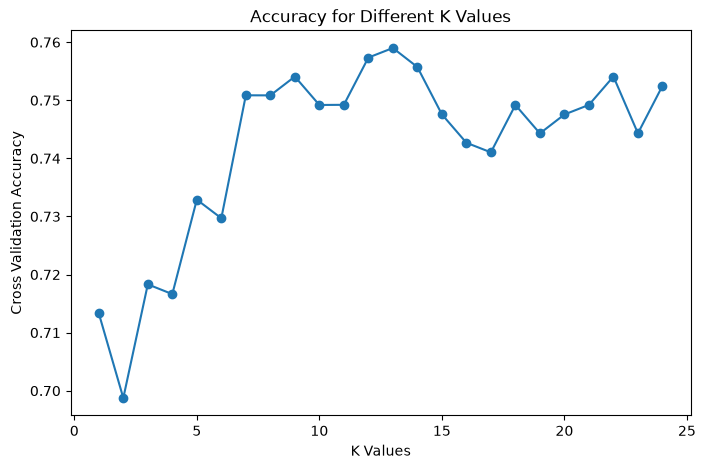

In [13]:
k_values = range(1, 25)
accuracy_values = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(
        model, X_train, y_train, cv=5, scoring='accuracy'
    )
    accuracy_values.append(scores.mean())

plt.figure(figsize=(8, 5))

plt.plot(k_values, accuracy_values, marker='o')

plt.xlabel("K Values")
plt.ylabel("Cross Validation Accuracy")
plt.title("Accuracy for Different K Values")

plt.show()